# 2D-FFT with Map-Reduce


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Assignment Tasks: 

The ultimate target is to write a Map-Reduce program, that computes the two dimensional fast Fourier transform (2D-FFT) by 

## Stage 1: FFT Basics

The fast Fourier transform (FFT) is an algorithm to transform a signal from the time domain to the frequency domain. 

### 1D-FFT

To gain a feeling for the FFT, we first have a look at the 1D FFT
Note, how after computing the FFT, the scale of the axis change. 

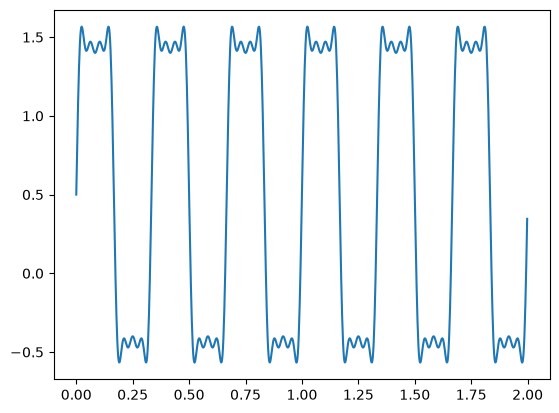

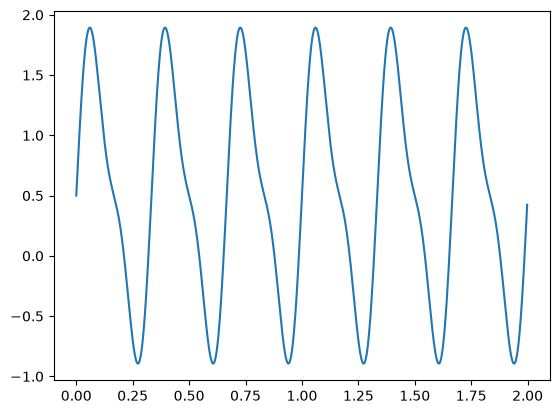

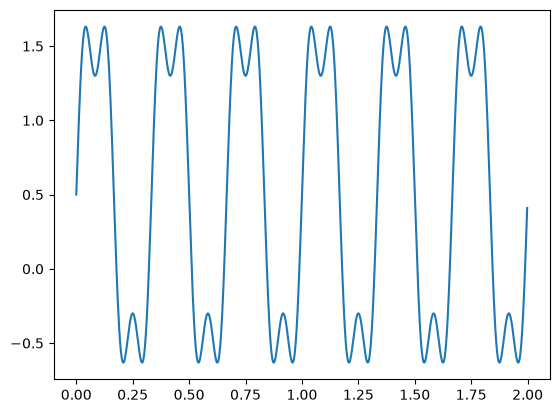

In [2]:
samples = 1000                               #how many samples do we want
sampletime = 2                               #how long do we sample the signal in seconds
timestep = 1/samples * sampletime            #how much time passes between each sample (in seconds)

t = np.arange(0, sampletime, timestep)       #time vector

theta = 0                                    #phase of sine function, in radians
F = 3                                       #frequency of sine function 
y1 = 1.2 * np.sin(2 * np.pi * F * t + theta);       #sine wave
y2 = 0.4 * np.sin(3 * 2 * np.pi * F * t + theta);
y3 = 0.2 * np.sin(5 * 2 * np.pi * F * t + theta);
y4 = 0.1 * np.sin(7 * 2 * np.pi * F * t + theta);
y = 0.5 + y1 + y2 + y3 + y4;

plt.plot(t, y)
plt.show() 

y1 = 1.2 * np.sin(2 * np.pi * F * t + theta);       #sine wave
y2 = 0.4 * np.sin(2 * 2 * np.pi * F * t + theta);
y = 0.5 + y1 + y2;

plt.plot(t, y)
plt.show() 

y1 = 1.2 * np.sin(2 * np.pi * F * t + theta);       #sine wave
y2 = 0.4 * np.sin(3 * 2 * np.pi * F * t + theta);
y = 0.5 + y1 + y2;

plt.plot(t, y)
plt.show() 

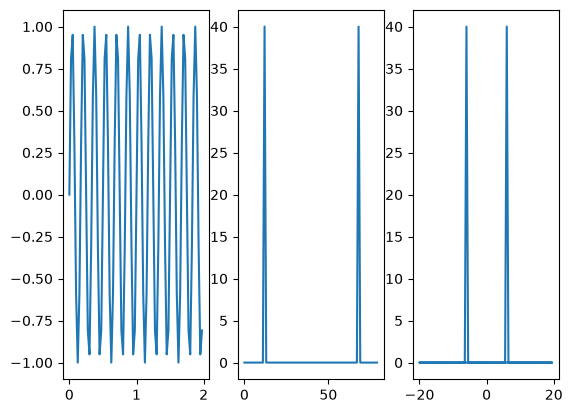

In [3]:
samples = 80                                 #how many samples do we want
sampletime = 2                               #how long do we sample the signal in seconds
timestep = 1/samples * sampletime            #how much time passes between each sample (in seconds)

t = np.arange(0, sampletime, timestep)       #time vector

theta = 0                                    #phase of sine function, in radians
F = 6                                       #frequency of sine function 
y = np.sin(2 * np.pi * F * t + theta);       #sine wave

fft = abs(np.fft.fft(y))                    
#fft = np.fft.fft(y)
#print(np.fft.fft(y))

freq = np.fft.fftfreq(samples, d=timestep)   #in the frequency domain, the x-axis has a different meaning
#print(freq)

plt.subplot(131)
plt.plot(t, y)

#without 
plt.subplot(132)
plt.plot(fft)

plt.subplot(133)
#plt.plot(freq[:8], fft[:8])
plt.plot(freq, fft)
plt.show() 

### Numpy native 2D-FFT 

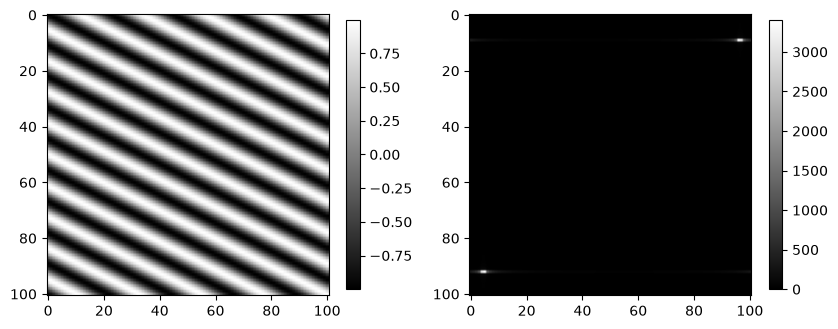

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors

x = np.arange(-50, 51, 1)
X, Y = np.meshgrid(x, x)
wavelength = 10
angle = 90
grating = np.sin(
    2*np.pi*(X*np.cos(angle) + Y*np.sin(angle)) / wavelength
)

fig, axs = plt.subplots(1, 2, figsize=(10, 10), sharex=True)

plt.set_cmap("gray")
pcm0 = axs[0].imshow(grating)
fig.colorbar(pcm0, ax=axs[0], shrink=0.35)


# Calculate Fourier transform of grating
#ft = np.fft.ifftshift(grating)
#ft = np.fft.fft2(ft)
#ft = np.fft.fftshift(ft)

ft = np.fft.fft2(grating)

pcm1 = axs[1].imshow(abs(ft))
fig.colorbar(pcm1, ax=axs[1], shrink=0.35)

#plt.xlim([480, 520])
#plt.ylim([520, 480])  # Note, order is reversed for y
plt.show()


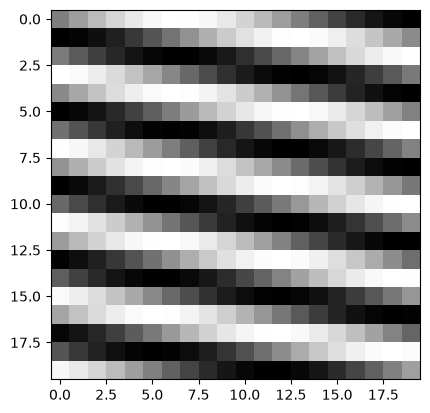

In [5]:
#see: https://thepythoncodingbook.com/2021/08/30/2d-fourier-transform-in-python-and-fourier-synthesis-of-images/
dim = 20
wavelength = 4
angle = 30 

x = np.arange(0, dim, 1)
X, Y = np.meshgrid(x, x)
image = np.sin(
    2*np.pi*(X*np.cos(angle) + Y*np.sin(angle)) / wavelength
)
plt.set_cmap("gray")
plt.imshow(image)


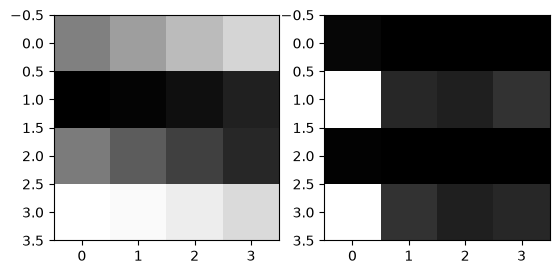

[[-0.19104445+0.00000000e+00j  0.01268238-6.93391606e-03j
   0.00966277+0.00000000e+00j  0.01268238+6.93391606e-03j]
 [ 2.8751376 +7.09641998e+00j -0.44842744+1.10561782e+00j
  -0.87068777+3.66339656e-01j -1.40565878-5.75444464e-01j]
 [-0.07789068+0.00000000e+00j -0.02199706+2.43407657e-02j
  -0.02282551+0.00000000e+00j -0.02199706-2.43407657e-02j]
 [ 2.8751376 -7.09641998e+00j -1.40565878+5.75444464e-01j
  -0.87068777-3.66339656e-01j -0.44842744-1.10561782e+00j]]
[[0.19104445 0.01445413 0.00966277 0.01445413]
 [7.65673513 1.19309595 0.94461735 1.51888543]
 [0.07789068 0.03280767 0.02282551 0.03280767]
 [7.65673513 1.51888543 0.94461735 1.19309595]]


In [6]:
dim = 4
wavelength = 4
angle = 30 
x = np.arange(0, dim, 1)
X, Y = np.meshgrid(x, x)
image = np.sin(2*np.pi*(X*np.cos(angle) + Y*np.sin(angle)) / wavelength)

ft = np.fft.fft2(image)

plt.set_cmap("gray")
plt.subplot(121)
plt.imshow(image)

plt.subplot(122)
plt.imshow(abs(ft))
plt.show()

print(ft)
print(abs(ft))

### Do-it-youself: serial implementation of a 2D-FFT consisting out of two 1D-FFTs

In [ ]:
#TODO serial implementation of a 2D-FFT consisting out of two 1D-FFTs


### Image: 
Güterbahnhof Wolfsburg

https://commons.wikimedia.org/wiki/File:G%C3%BCterbahnhof_Wolfurt_Satellitenbild_mit_Verkehrsnetz.jpg

(C) Creative Commons



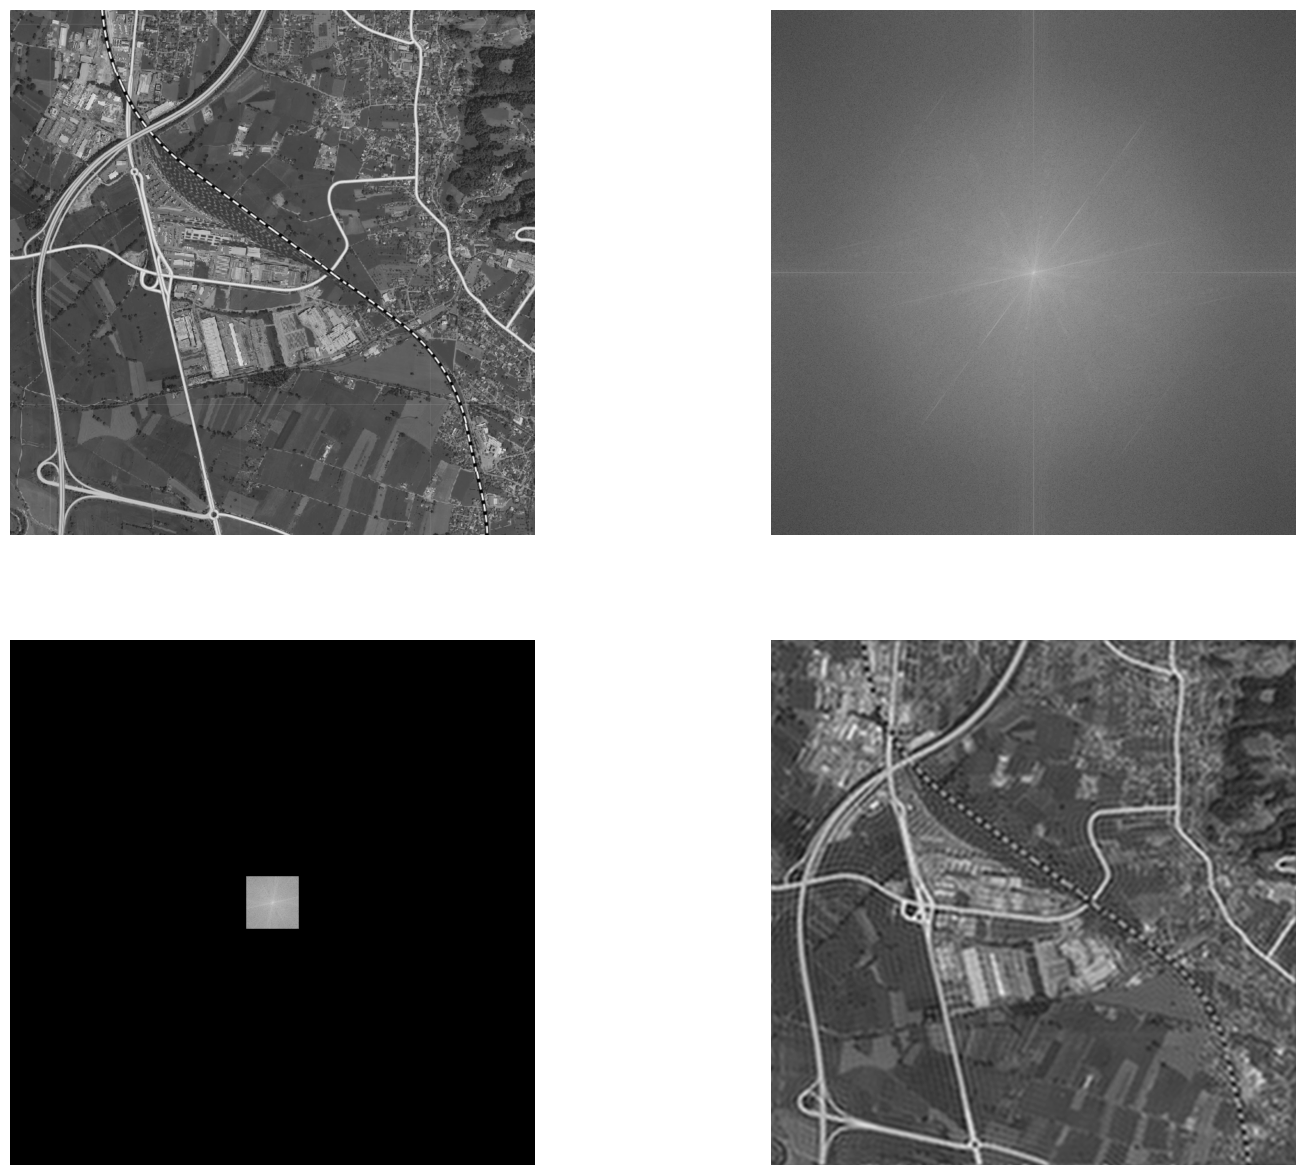

In [16]:
image_filename = "img.jpg"

image_dimension = 1498  #Image has 1498 x 1498 pixels = 2244004
#print(image_dimension)
compression_rate = 0.01 #0.01 = 1%
compressed_dimension = int(np.sqrt(compression_rate * (image_dimension * image_dimension)))
#print(compressed_dimension)
frame = int((image_dimension - compressed_dimension)/2)
#print(frame)

def remove_high_frequencies_unshifted(img, border):
    #img[:border*2, :] = 0
    img[-border*2:, :] = 0
    #img[:, :border*2] = 0
    #img[:, -border*2:] = 0
    return img

def remove_high_frequencies_black(img, border):
    img[:border, :] = 1
    img[-border:, :] = 1
    img[:, :border] = 1
    img[:, -border:] = 1
    return img

def remove_high_frequencies_white(img, border):
    img[:border, :] = 0
    img[-border:, :] = 0
    img[:, :border] = 0
    img[:, -border:] = 0
    return img

def comp_2dft(input):
    ft = np.fft.ifftshift(input)
    ft = np.fft.fft2(ft)
    return np.fft.fftshift(ft)

def comp_2dift(input):
    ift = np.fft.ifftshift(input)
    ift = np.fft.ifft2(ift)
    return np.fft.fftshift(ift)

# Read and process image
image = plt.imread(image_filename)
image = image[:, :, :3].mean(axis=2)  # Convert to grayscale

ft = comp_2dft(image)
padded = remove_high_frequencies_black(ft.copy(), frame)
ift = comp_2dift(padded)

plt.figure(figsize=(18,15))
plt.set_cmap("gray")

plt.subplot(221)
plt.imshow(image)
plt.axis("off")

plt.subplot(222)
plt.imshow(np.log(abs(ft)))
plt.axis("off")

plt.subplot(223)
plt.imshow(np.log(abs(padded)))
plt.axis("off")

plt.subplot(224)
plt.imshow(abs(ift))
plt.axis("off")
plt.show()


# Task 1: Implement the Mapper

### Now we have to write the code for the mapper function.   
TBD

In [9]:
#!/usr/bin/env python

import sys 
import numpy as np

def mapper(textinput):
    #TODO
    return ""

# Task 2: Implement the Reducer

TBD

### Write the reducer   
   
TBD

It outputs the result of the 2D-FFT column-wise. 

In [10]:
input = "1, 2, 3, 4, 5\n6, 7, 8, 9, 10\n11, 12, 13, 14, 15\n16, 17, 18, 19, 20\n21, 22, 23, 24, 25"
output = mapper(input);
output=sorted(output.split('\n'));
output='\n'.join(output);

In [11]:
#!/usr/bin/env python
#Reducer.py
import sys

column_temp = {}

def reducer(textinput):
    #TODO
    return ""

# Task 3: Test the Full "Pipeline" Without Hadoop Streaming

### Tiny Test Case

TBD

In [12]:
input = "1, 2, 3, 4, 5\n6, 7, 8, 9, 10\n11, 12, 13, 14, 15\n16, 17, 18, 19, 20\n21, 22, 23, 24, 25"
output = mapper(input);
output=sorted(output.split('\n'))
output='\n'.join(output)
print("Reducer Output: \n============================\n")
output = reducer(output)

Reducer Output: 



# Task 4: Plot and Validate the Results 

### Now use the visualization function to plot our results

In [13]:
#TODO